# 07 · Time-series analysis and order-volume forecasting
**Owner:** P1 (Weather Data & Forecasting) · **Tasks:** T04 data preparation, T05 forecasting models, T06 evaluation ·
**Rubric:** Review 2, time-series method: preparation and implementation (2), evaluation and interpretation (3)

**Question.** Can next week's daily order volume of the Surabaya F&B outlet be forecast, and does knowing the weather improve
the forecast?

**Data.** Daily weather for Surabaya from Open-Meteo (`data/raw/weather.csv`) joined to `data/raw/daily_orders.csv`, which holds
731 days: **272 real POS days (2 Jan – 30 Sep 2025)** and **459 synthetic days** (2024 and Q4 2025) generated from the real
base by P2 (`docs/generator.md`). The column `is_synthetic` marks them.

**Rule used throughout: only real days are scored.** The synthetic days have no day-to-day memory (shown in section 3), so
a forecast of them says nothing about forecasting a real outlet. They are used in one place only: as optional extra training
history, in section T06.4.

**Plan.** 1) prepare and test the real series, 2) fit baselines and two model families with and without weather,
3) compare them with a rolling-origin backtest, 4) check significance, weather effect, residuals, segments, and translate the
error into a planning buffer.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import forecast as F
import plotstyle as S
S.apply()

RES = ROOT / "results"; RES.mkdir(exist_ok=True)
def save(fig, name):
    fig.savefig(RES / f"{name}.png", dpi=160, bbox_inches="tight")

# ---- configuration -------------------------------------------------------------------------
WEATHER_CSV = ROOT / "data/raw/weather.csv"
ORDERS_CSV  = ROOT / "data/raw/daily_orders.csv"
INITIAL = 127          # real days before the first forecast day (9 May 2025, the same first test day as P5)
HORIZON, STEP = 7, 7   # 7-day forecasts, origin moved forward one week at a time
TEST_DAYS = 56         # static hold-out: last 8 weeks of the real series

## T04 · Data preparation
### 1. Load and check the data

In [2]:
df_all = F.load_daily(WEATHER_CSV, ORDERS_CSV)
assert df_all["order_count"].notna().all(), "orders missing for some days"
display(F.data_quality(df_all).to_frame("value"))

real = df_all[df_all["is_synthetic"] == 0]                 # 272 real POS days: the only days that are scored
hist = df_all.loc[:real.index.max()]                       # synthetic 2024 + 1 Jan 2025, then the real days
N_PREFIX = int((hist["is_synthetic"] == 1).sum())          # synthetic rows before the first real day
assert real.index.is_monotonic_increasing and (real.index.to_series().diff().dropna() == pd.Timedelta("1D")).all()
print(f"real series: {real.index.min().date()} → {real.index.max().date()} ({len(real)} days, no gaps)")
print(f"synthetic history before it: {N_PREFIX} days; synthetic Q4 2025 after it is never used")
display(real[["order_count", "precip_mm", "temp_max_c", "is_rainy", "heavy_rain", "is_hot", "is_festival", "dow", "regime"]].head())

,value
days,731
start,2024-01-01
end,2025-12-31
real_days,272
synthetic_days,459
missing_order_days,0
missing_weather_cells,0
min_orders,114.0
max_orders,296.0


real series: 2025-01-02 → 2025-09-30 (272 days, no gaps)
synthetic history before it: 367 days; synthetic Q4 2025 after it is never used


,order_count,precip_mm,temp_max_c,is_rainy,heavy_rain,is_hot,is_festival,dow,regime
date,,,,,,,,,
2025-01-02,191.0,15.0,29.5,1,1,0,0,3,rainy
2025-01-03,203.0,1.4,31.7,0,0,0,0,4,normal
2025-01-04,177.0,9.0,30.5,1,0,0,0,5,rainy
2025-01-05,188.0,17.4,30.1,1,1,0,0,6,rainy
2025-01-06,168.0,14.4,30.9,1,0,0,0,0,rainy


### 2. The series
Real days in dark, synthetic history in light gray. Blue dots are real rainy days (≥ 2.5 mm).

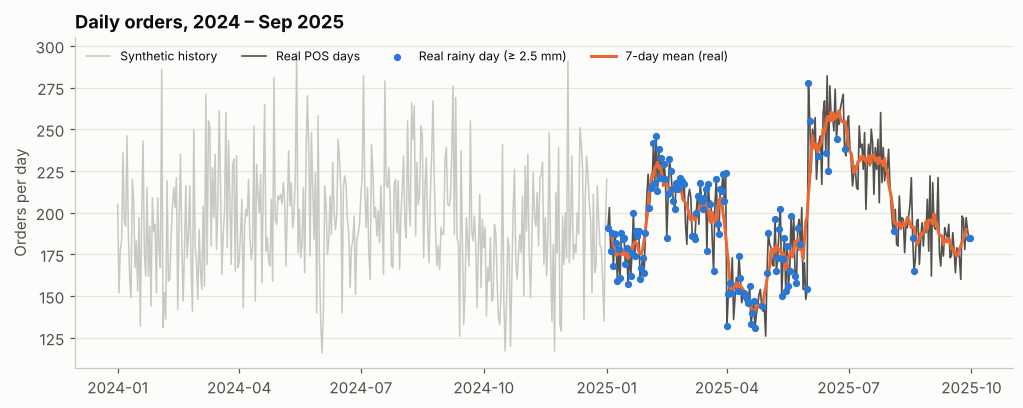

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.9))
syn = hist[hist["is_synthetic"] == 1]
ax.plot(syn.index, syn["order_count"], color=S.C["light"], lw=1, label="Synthetic history")
ax.plot(real.index, real["order_count"], color=S.C["ink2"], lw=1.1, label="Real POS days")
r = real[real["is_rainy"] == 1]
ax.scatter(r.index, r["order_count"], s=14, color=S.C["blue"], zorder=3, label="Real rainy day (≥ 2.5 mm)")
ax.plot(real.index, real["order_count"].rolling(7, center=True).mean(), color=S.C["orange"], lw=2, label="7-day mean (real)")
ax.set_ylabel("Orders per day"); ax.set_title("Daily orders, 2024 – Sep 2025")
ax.legend(ncol=4, loc="upper left", fontsize=8)
save(fig, "fig01_series"); plt.show()

### 3. What kind of series is this?
Two checks decide how the data may be used. **Memory:** does today's value predict tomorrow's? **Weekly pattern:** do weekdays differ?

In [4]:
from statsmodels.tsa.stattools import acf
syn24 = hist.loc[:"2024-12-31"]
mem = pd.DataFrame({
    "real (272 days)": acf(real["order_count"], nlags=7)[[1, 7]],
    "synthetic 2024 (366 days)": acf(syn24["order_count"], nlags=7)[[1, 7]],
}, index=["autocorrelation lag 1", "autocorrelation lag 7"]).round(2)
display(mem)

dow_tab = real.groupby("dow")["order_count"].agg(["count", "mean"]).round(1)
dow_tab.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
display(dow_tab.T)

,real (272 days),synthetic 2024 (366 days)
autocorrelation lag 1,0.77,0.08
autocorrelation lag 7,0.64,0.16


,Mon,Tue,Wed,Thu,Fri,Sat,Sun
count,39.0,39.0,38.0,39.0,39.0,39.0,39.0
mean,195.9,197.2,198.1,197.3,200.7,195.0,200.8


Real days carry strong memory (about 0.77 at lag 1); synthetic days have almost none, because the generator draws each day
independently around its expected value. A time-series model has nothing to learn from that, which is why synthetic days are not
scored. The real weekday means are nearly flat, so the weekly pattern is weak; this is checked formally in the decomposition below.

,days,mean,median,std
regime,,,,
hot,12,172.9,177.0,21.8
normal,137,207.3,205.0,33.9
rainy,123,189.8,187.0,29.6


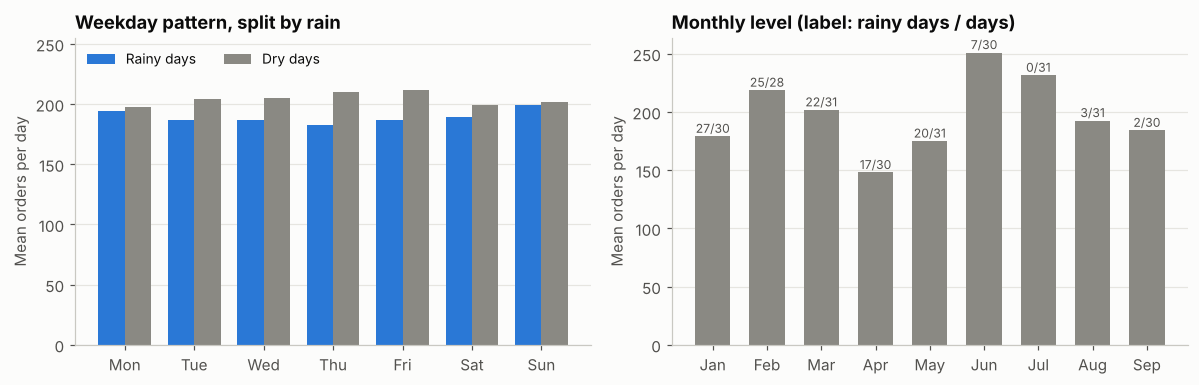

date,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep
mean_orders,179.1,218.7,201.8,148.0,175.0,251.0,231.5,192.6,184.2
rainy_days,27.0,25.0,22.0,17.0,20.0,7.0,0.0,3.0,2.0
days,30.0,28.0,31.0,30.0,31.0,30.0,31.0,31.0,30.0


In [5]:
g = real.groupby("regime")["order_count"].agg(days="count", mean="mean", median="median", std="std").round(1)
display(g)
mon = real.groupby(real.index.month).agg(mean_orders=("order_count", "mean"), rainy_days=("is_rainy", "sum"), days=("is_rainy", "size"))
mon.index = pd.to_datetime(mon.index, format="%m").strftime("%b")
mon = mon.round(1)

pv = real.assign(rain=np.where(real["is_rainy"] == 1, "rainy", "dry")).pivot_table(index="dow", columns="rain", values="order_count", aggfunc="mean")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(7); w = 0.38
axes[0].bar(x - w/2, pv["rainy"], w, color=S.C["blue"], label="Rainy days")
axes[0].bar(x + w/2, pv["dry"], w, color=S.C["gray"], label="Dry days")
axes[0].set_xticks(x, ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]); axes[0].set_ylabel("Mean orders per day")
axes[0].set_ylim(0, 255); axes[0].set_title("Weekday pattern, split by rain"); axes[0].legend(ncol=2, loc="upper left")
axes[1].bar(mon.index, mon["mean_orders"], color=S.C["gray"], width=0.65)
for i, (m, row) in enumerate(mon.iterrows()):
    axes[1].text(i, row["mean_orders"] + 3, f"{int(row['rainy_days'])}/{int(row['days'])}", ha="center", fontsize=8, color=S.C["ink2"])
axes[1].set_ylabel("Mean orders per day"); axes[1].set_title("Monthly level (label: rainy days / days)")
fig.tight_layout(); save(fig, "fig02_weekday_rain"); plt.show()
display(mon.T)

The monthly level moves far more than the weekday pattern (for example April is low and June is high), and rainy days are
concentrated in the early months. Any raw "rainy vs dry" gap therefore mixes the effect of rain with the slow drift in
the level. The model-based weather estimate in T06.3 controls for that drift; the raw gap does not.

### 4. Stationarity
ADF tests the null of a unit root; KPSS tests the null of stationarity. Both are run on the real series.

In [6]:
st = F.stationarity_tests(real["order_count"])
display(st.round(4))

,test,statistic,p_value,reading
0,ADF,-2.5035,0.1146,cannot reject unit root
1,KPSS (level),0.2788,0.1000,stationary not rejected


Reading both tests together: ADF cannot reject a unit root and KPSS does not reject stationarity, so neither test gives a clear
answer on 272 points. The series has a slowly moving level, which an AR term in the model can follow, so the models use `d = 0`
and rely on the ARMA part for the drift rather than differencing the data.

### 5. Seasonal decomposition and autocorrelation
Additive decomposition with a weekly period (7).

Weekly seasonal strength: 0.02 (0 = none, 1 = pure seasonality)
Correlation of the remainder with same-day rainfall: -0.09


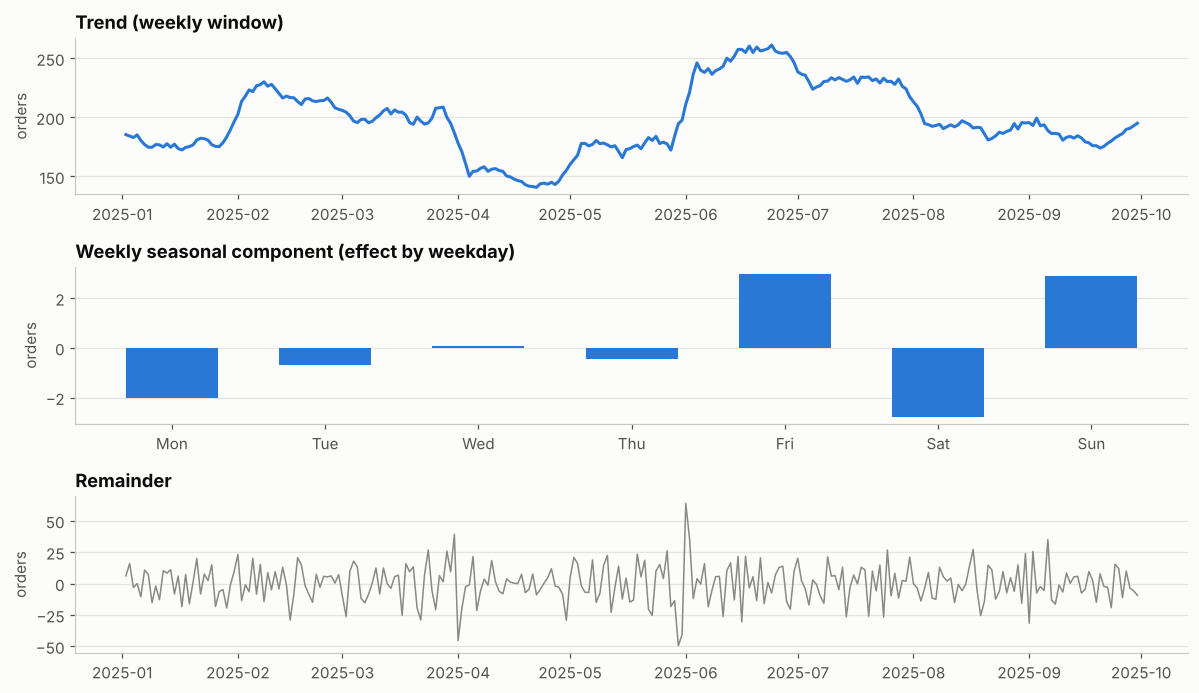

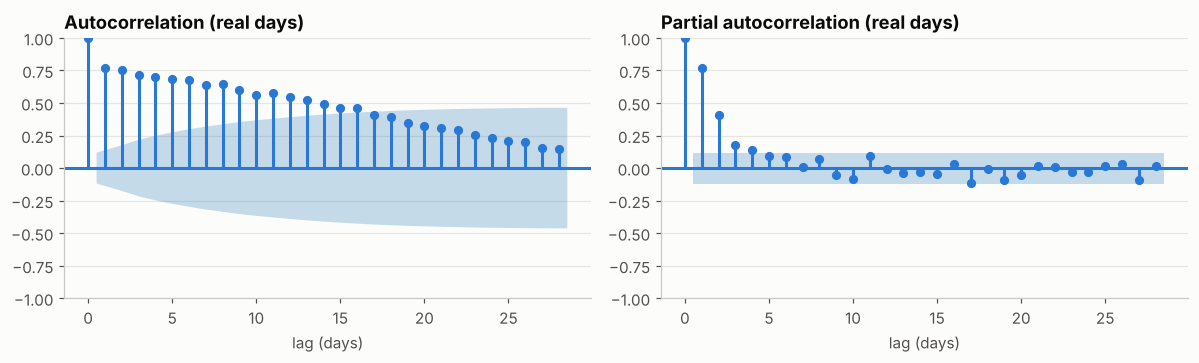

In [7]:
dec = F.decompose(real["order_count"], period=7)
fs = F.weekly_strength(dec)
rem = dec.resid.dropna()
print(f"Weekly seasonal strength: {fs:.2f} (0 = none, 1 = pure seasonality)")
print(f"Correlation of the remainder with same-day rainfall: {np.corrcoef(rem, real.loc[rem.index, 'precip_mm'])[0, 1]:.2f}")

fig, axes = plt.subplots(3, 1, figsize=(11, 6.4), sharex=False)
axes[0].plot(dec.trend.index, dec.trend, color=S.C["blue"]); axes[0].set_title("Trend (weekly window)")
sea = dec.seasonal.groupby(dec.seasonal.index.dayofweek).mean()
axes[1].bar(range(7), sea.values, color=S.C["blue"], width=0.6)
axes[1].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[1].set_title("Weekly seasonal component (effect by weekday)")
axes[2].plot(dec.resid.index, dec.resid, color=S.C["gray"], lw=1); axes[2].set_title("Remainder")
for a in axes: a.set_ylabel("orders")
fig.tight_layout(); save(fig, "fig03_decomposition"); plt.show()

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
plot_acf(real["order_count"], lags=28, ax=axes[0], color=S.C["blue"], vlines_kwargs={"colors": S.C["blue"]}, alpha=0.05)
plot_pacf(real["order_count"], lags=28, ax=axes[1], color=S.C["blue"], vlines_kwargs={"colors": S.C["blue"]}, alpha=0.05, method="ywm")
axes[0].set_title("Autocorrelation (real days)"); axes[1].set_title("Partial autocorrelation (real days)")
for a in axes: a.set_xlabel("lag (days)")
fig.tight_layout(); save(fig, "fig17_acf_pacf"); plt.show()

The weekly component is close to zero (seasonal strength about 0.02): in this outlet's real data, the day of the week explains
almost nothing. What is left is a slowly varying level: the autocorrelation decays slowly and the partial autocorrelation is large at lags 1 and 2 and
small after that. That is the signature of a low-order autoregressive series (the AIC search also settles on AR(2)), and it is why a
recent-average baseline is hard to beat.

### 6. Time-ordered split
No shuffling. The first `INITIAL` real days are used only to choose model settings; the rest are forecast one week at a time.
The last 8 weeks are also used for a separate fit-once hold-out.

settings chosen on : 2025-01-02 → 2025-05-08 (127 days)
scored (backtest)  : 2025-05-09 → 2025-09-30 (145 days, 21 weekly folds)


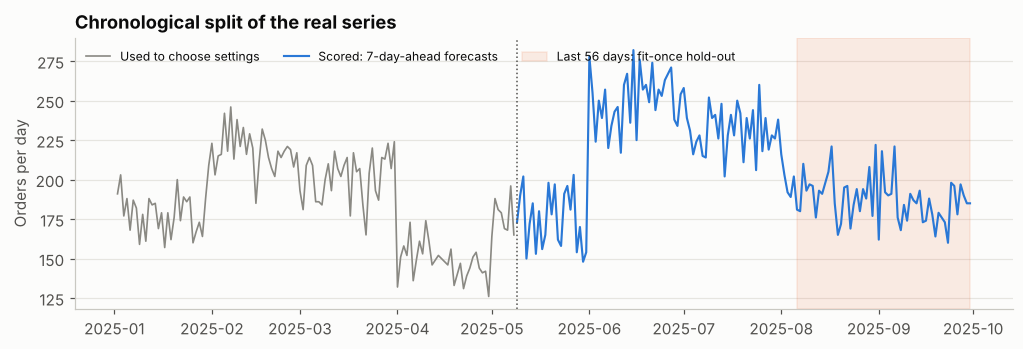

In [8]:
train0, test0 = real.iloc[:INITIAL], real.iloc[INITIAL:]
print(f"settings chosen on : {train0.index.min().date()} → {train0.index.max().date()} ({len(train0)} days)")
print(f"scored (backtest)  : {test0.index.min().date()} → {test0.index.max().date()} ({len(test0)} days, {int(np.ceil(len(test0) / STEP))} weekly folds)")
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(train0.index, train0["order_count"], color=S.C["gray"], lw=1.1, label="Used to choose settings")
ax.plot(test0.index, test0["order_count"], color=S.C["blue"], lw=1.4, label="Scored: 7-day-ahead forecasts")
ax.axvspan(real.index[-TEST_DAYS], real.index[-1], color=S.C["orange"], alpha=0.12, label=f"Last {TEST_DAYS} days: fit-once hold-out")
ax.axvline(test0.index[0], color=S.C["ink2"], lw=1, ls=":")
ax.set_ylabel("Orders per day"); ax.set_title("Chronological split of the real series"); ax.legend(ncol=3, loc="upper left", fontsize=8)
save(fig, "fig04_split"); plt.show()

## T05 · Forecasting models
| Model | What it does | Uses weather? |
|---|---|---|
| Seasonal naive | repeats the last observed week | no |
| Weekday mean | average of each weekday over the training window | no |
| 7-day mean | mean of the last 7 days, held flat for the next 7 | no |
| SARIMAX (no weather) | festival flag, ARMA errors; weekday dummies kept only if AIC supports them | no |
| SARIMAX (weather) | the same, plus rain, heavy-rain and hot-day flags | yes |
| Prophet (no weather) | trend + weekly seasonality + festival flag | no |
| Prophet (weather) | the same plus the three weather flags | yes |

Settings (ARMA order, whether to keep weekday dummies, Prophet trend flexibility) are chosen **on the first 127 days only**,
before any scored day is seen. Weather flags use the team thresholds (rain ≥ 2.5 mm, heavy ≥ 15 mm, hot ≥ 33 °C).

**Weather is oracle weather.** Each forecast day is given its *observed* weather. A live system would use a weather forecast,
so the weather models' accuracy here is a best case.

In [9]:
def build_models(init):
    """Choose all model settings from `init` only and return {name: model function} plus a summary table."""
    sw, tw = F.select_sarimax_order(init, weather=True)
    sn, tn = F.select_sarimax_order(init, weather=False)
    cw, scw = F.select_prophet_cps(init, weather=True)
    cn, scn = F.select_prophet_cps(init, weather=False)
    models = {
        "Seasonal naive":       F.seasonal_naive,
        "Weekday mean":         F.weekday_mean,
        "7-day mean":           F.rolling_mean7,
        "SARIMAX (no weather)": F.make_sarimax(sn),
        "SARIMAX (weather)":    F.make_sarimax(sw),
        "Prophet (no weather)": F.make_prophet(False, cn),
        "Prophet (weather)":    F.make_prophet(True, cw),
    }
    summary = pd.DataFrame([
        ["SARIMAX (no weather)", f"order {sn.order}, seasonal {sn.seasonal_order}, weekday dummies {sn.dow}", tn["aic"].iloc[0]],
        ["SARIMAX (weather)",    f"order {sw.order}, seasonal {sw.seasonal_order}, weekday dummies {sw.dow}", tw["aic"].iloc[0]],
        ["Prophet (no weather)", f"changepoint_prior_scale {cn}", np.nan],
        ["Prophet (weather)",    f"changepoint_prior_scale {cw}", np.nan],
    ], columns=["model", "chosen settings", "AIC on initial window"])
    return models, summary, {"sarimax_weather": tw, "sarimax_none": tn}

models, chosen, tabs = build_models(real.iloc[:INITIAL])
display(chosen.round(1))
print("SARIMAX (weather) - three lowest-AIC candidates:"); display(tabs["sarimax_weather"].head(3).round(1))

11:00:31 - cmdstanpy - INFO - Chain [1] start processing


11:00:31 - cmdstanpy - INFO - Chain [1] done processing


,model,chosen settings,AIC on initial window
0,SARIMAX (no weather),"order (2, 0, 0), seasonal (1, 0, 0, 7), weekda...",1018.3
1,SARIMAX (weather),"order (2, 0, 0), seasonal (1, 0, 0, 7), weekda...",1021.8
2,Prophet (no weather),changepoint_prior_scale 0.05,NaN
3,Prophet (weather),changepoint_prior_scale 0.05,NaN


SARIMAX (weather) - three lowest-AIC candidates:


,order,seasonal,dow_dummies,aic,bic
0,"(2, 0, 0)","(1, 0, 0, 7)",False,1021.8,1046.8
1,"(1, 0, 1)","(1, 0, 0, 7)",False,1023.8,1048.9
2,"(1, 0, 0)","(1, 0, 0, 7)",False,1036.5,1058.8


In [10]:
fc = F.rolling_origin(real, models, initial=INITIAL, horizon=HORIZON, step=STEP)
fc.to_csv(RES / "backtest_forecasts.csv", index=False)
print(f"{fc['date'].nunique()} scored real days x {len(models)} models; first forecast day {fc['date'].min():%Y-%m-%d}, last {fc['date'].max():%Y-%m-%d}")

  fold 5/21 (origin 2025-06-06)


  fold 10/21 (origin 2025-07-11)


  fold 15/21 (origin 2025-08-15)


  fold 20/21 (origin 2025-09-19)


  fold 21/21 (origin 2025-09-26)
145 scored real days x 7 models; first forecast day 2025-05-09, last 2025-09-30


### Forecast versus actual, last 8 weeks of the backtest

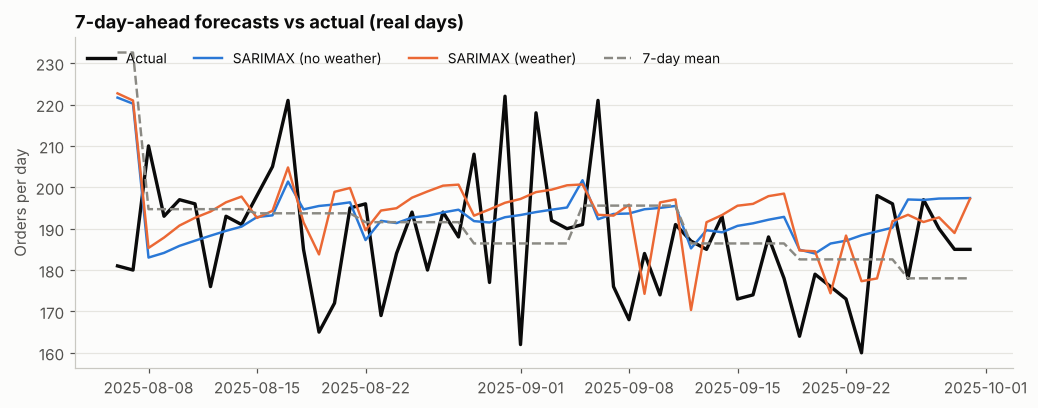

In [11]:
M = F.metrics(fc).sort_values("MAE")
fitted = [m for m in M.index if m.startswith(("SARIMAX", "Prophet"))]
best_model = fitted[0]                      # lowest-MAE fitted model (the baselines are reported separately)
last = fc["date"].sort_values().unique()[-TEST_DAYS:]
fig, ax = plt.subplots(figsize=(11, 3.9))
act = fc[fc["model"] == best_model].set_index("date").loc[last]
ax.plot(act.index, act["y"], color=S.C["ink"], lw=2.2, label="Actual")
others = [m for m in ("SARIMAX (weather)", "SARIMAX (no weather)") if m != best_model][:1]
for name, col, ls in [(best_model, S.C["blue"], "-")] + [(m, S.C["orange"], "-") for m in others] + [("7-day mean", S.C["gray"], "--")]:
    p = fc[fc["model"] == name].set_index("date").loc[last]
    ax.plot(p.index, p["yhat"], color=col, lw=1.6, ls=ls, label=name)
ax.set_ylabel("Orders per day"); ax.set_title("7-day-ahead forecasts vs actual (real days)")
ax.legend(ncol=4, loc="upper left")
save(fig, "fig05_forecast_vs_actual"); plt.show()

## T06 · Evaluation and interpretation
### 1. Accuracy over the whole backtest
MAE and RMSE are in orders per day; MAPE is relative to actual orders. `cover80_%` is the share of days inside the model's own 80 %
prediction interval (should be near 80).

,n,MAE,RMSE,MAPE_%,bias,cover80_%,MAE_%_of_mean,"MAE vs weekday mean, %"
model,,,,,,,,
7-day mean,145,17.15,23.08,8.25,0.31,NaN,8.23,-41.90
SARIMAX (no weather),145,18.38,24.63,8.68,4.67,87.59,8.82,-37.74
SARIMAX (weather),145,18.91,24.98,8.94,4.48,82.76,9.07,-35.94
Seasonal naive,145,22.42,29.08,10.74,0.57,NaN,10.76,-24.06
Weekday mean,145,29.52,37.03,13.46,13.81,NaN,14.17,0.00
Prophet (no weather),145,30.66,38.13,14.71,-5.07,57.24,14.71,3.85
Prophet (weather),145,31.76,38.44,15.29,-3.14,55.17,15.24,7.59


mean daily orders over the scored days: 208.4


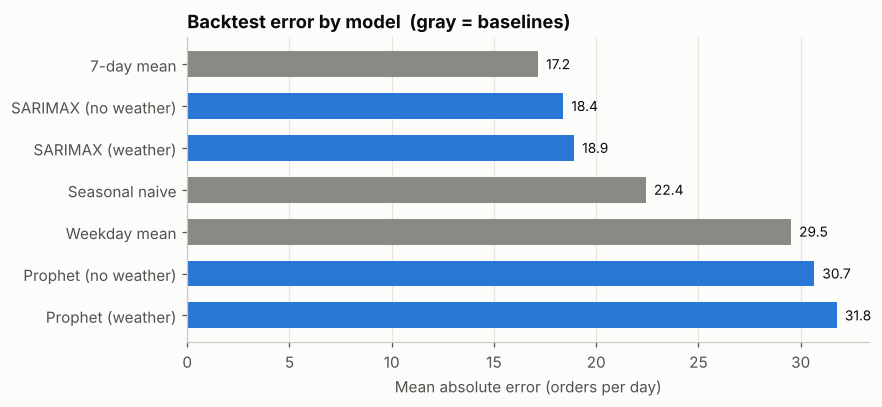

In [12]:
mean_orders = float(fc.drop_duplicates("date")["y"].mean())
M["MAE_%_of_mean"] = M["MAE"] / mean_orders * 100
base = M.loc["Weekday mean", "MAE"]
M["MAE vs weekday mean, %"] = (M["MAE"] / base - 1) * 100
display(M.round(2))
M.round(3).to_csv(RES / "metrics_overall.csv")
print(f"mean daily orders over the scored days: {mean_orders:.1f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
order = M.index[::-1]
cols = [S.C["gray"] if m in ("Seasonal naive", "Weekday mean", "7-day mean") else S.C["blue"] for m in order]
bars = ax.barh(order, M.loc[order, "MAE"], color=cols, height=0.62)
for b, v in zip(bars, M.loc[order, "MAE"]):
    ax.text(v + 0.4, b.get_y() + b.get_height() / 2, f"{v:.1f}", va="center", color=S.C["ink"], fontsize=9)
ax.set_xlabel("Mean absolute error (orders per day)"); ax.set_title("Backtest error by model  (gray = baselines)")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
save(fig, "fig06_mae_by_model"); plt.show()

### 2. Are the differences real?
Paired **block** bootstrap over forecast days (blocks of 7 consecutive days, because forecast errors of neighbouring days are
correlated). The interval is for `MAE(a) − MAE(b)`: negative means `a` is better; an interval that includes 0 means the data cannot
separate the two models.

In [13]:
pairs = [
    (best_model, "7-day mean"),
    (best_model, "Weekday mean"),
    (best_model, "Seasonal naive"),
    ("SARIMAX (weather)", "SARIMAX (no weather)"),
    ("Prophet (weather)", "Prophet (no weather)"),
    ("SARIMAX (no weather)", "Prophet (no weather)"),
]
seen, rows = set(), []
for a, b in pairs:
    if a == b or (a, b) in seen: continue
    seen.add((a, b)); rows.append(F.paired_bootstrap_mae_diff(fc, a, b))
B = pd.DataFrame(rows)
B["ci95_low"] = B["ci95"].map(lambda t: t[0]); B["ci95_high"] = B["ci95"].map(lambda t: t[1])
B["separable"] = np.where((B["ci95_low"] > 0) | (B["ci95_high"] < 0), "yes", "no")
B = B.drop(columns="ci95")
display(B.round(2)); B.round(3).to_csv(RES / "bootstrap_comparisons.csv", index=False)

,a,b,mae_diff,share_boot_a_better,ci95_low,ci95_high,separable
0,SARIMAX (no weather),7-day mean,1.23,0.13,-1.04,3.32,no
1,SARIMAX (no weather),Weekday mean,-11.14,1.00,-18.08,-5.17,yes
2,SARIMAX (no weather),Seasonal naive,-4.04,1.00,-7.29,-1.30,yes
3,SARIMAX (weather),SARIMAX (no weather),0.53,0.04,-0.10,1.35,no
4,Prophet (weather),Prophet (no weather),1.10,0.18,-0.87,2.77,no
5,SARIMAX (no weather),Prophet (no weather),-12.28,1.00,-18.00,-7.03,yes


### 3. Does weather help? Forecast gain and estimated effect
Two different questions. **(a) Forecast gain:** does adding the weather flags lower the out-of-sample error? (rows 4–5 above).
**(b) Effect size:** how large is the weather effect in the data? The SARIMAX below is fitted once on all 272 real days
(inference, not forecasting) on log orders, so coefficients are proportional effects. The ARMA part absorbs the slow level drift,
so the effects are measured against recent demand and not against the whole-period average.
Heavy-rain days also carry the rain flag, so the heavy-rain coefficient is the *extra* effect beyond ordinary rain.

model used: ((1, 0, 1), (0, 0, 0, 0), False)


,coef,ci_low,ci_high,p_value,n_days_flag,pct_effect,pct_low,pct_high
term,,,,,,,,
is_rainy,-0.014,-0.050,0.021,0.426,123,-1.439,-4.892,2.139
heavy_rain,-0.040,-0.073,-0.006,0.019,30,-3.905,-7.064,-0.640
is_hot,-0.043,-0.129,0.043,0.325,13,-4.233,-12.134,4.378
is_festival,0.028,-0.002,0.058,0.065,15,2.836,-0.171,5.933


Raw gap, not adjusted for the level drift: rainy days 189.8 vs dry 204.5 (-7.2%)


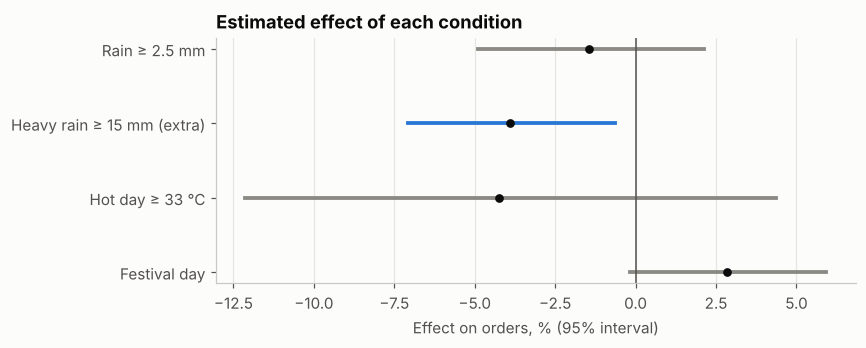

In [14]:
W = F.weather_effect(real, log=True, order_window=INITIAL)
print("model used:", W.attrs["order"])
display(W.round(3)); W.round(4).to_csv(RES / "weather_effect.csv")

raw = real.groupby("is_rainy")["order_count"].agg(days="count", mean="mean").round(1)
raw.index = ["dry", "rainy"]
print(f"Raw gap, not adjusted for the level drift: rainy days {raw.loc['rainy','mean']:.1f} vs dry {raw.loc['dry','mean']:.1f} "
      f"({(raw.loc['rainy','mean'] / raw.loc['dry','mean'] - 1) * 100:+.1f}%)")

fig, ax = plt.subplots(figsize=(7.5, 2.9))
terms = ["is_rainy", "heavy_rain", "is_hot", "is_festival"]
labels = ["Rain ≥ 2.5 mm", "Heavy rain ≥ 15 mm (extra)", "Hot day ≥ 33 °C", "Festival day"]
yv = np.arange(len(terms))[::-1]
for yy, t in zip(yv, terms):
    sig = not (W.loc[t, "pct_low"] <= 0 <= W.loc[t, "pct_high"])
    ax.plot([W.loc[t, "pct_low"], W.loc[t, "pct_high"]], [yy, yy], color=S.C["blue"] if sig else S.C["gray"], lw=2.5)
    ax.scatter(W.loc[t, "pct_effect"], yy, color=S.C["ink"], zorder=3, s=22)
ax.axvline(0, color=S.C["ink2"], lw=1); ax.set_yticks(yv, labels)
ax.set_xlabel("Effect on orders, % (95% interval)"); ax.set_title("Estimated effect of each condition")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
save(fig, "fig19_weather_effect"); plt.show()

### 4. Does synthetic history help the real-day forecasts?
Same scored days (9 May – 30 Sep 2025), same models, but training now also includes the 367 synthetic days before 2 Jan 2025.
Settings are re-chosen on the longer initial window.

**Caveat that favours this variant:** the synthetic days were generated from parameters estimated on all 272 real days,
including the days being scored here, so this variant has seen information about the test period. If it still does not
help, the conclusion is safe; if it helps, the gain is overstated.

In [15]:
modelsB, chosenB, _ = build_models(hist.iloc[:N_PREFIX + INITIAL])
display(chosenB.round(1))
fcB = F.rolling_origin(hist, modelsB, initial=N_PREFIX + INITIAL, horizon=HORIZON, step=STEP, verbose=False)
assert set(fcB["date"]) == set(fc["date"]) and (fcB["date"].map(real["is_synthetic"]) == 0).all(), "scored days must be the same real days"
fcB.to_csv(RES / "backtest_forecasts_synthetic_history.csv", index=False)

MB = F.metrics(fcB)
cmp_ = pd.DataFrame({"MAE real-only training": M["MAE"], "MAE with synthetic history": MB["MAE"].reindex(M.index)})
cmp_["change"] = cmp_["MAE with synthetic history"] - cmp_["MAE real-only training"]
rowsB = []
for m in [x for x in M.index if x not in ("Seasonal naive", "7-day mean")]:
    a = fcB[fcB["model"] == m].assign(model=f"{m} + synthetic")
    both = pd.concat([fc[fc["model"] == m], a])
    r_ = F.paired_bootstrap_mae_diff(both, f"{m} + synthetic", m)
    rowsB.append({"model": m, "ci95_low": r_["ci95"][0], "ci95_high": r_["ci95"][1]})
cmp_ = cmp_.join(pd.DataFrame(rowsB).set_index("model"))
cmp_["separable"] = np.where((cmp_["ci95_low"] > 0) | (cmp_["ci95_high"] < 0), "yes", np.where(cmp_["ci95_low"].isna(), "", "no"))
display(cmp_.round(2)); cmp_.round(3).to_csv(RES / "metrics_synthetic_history.csv")

,model,chosen settings,AIC on initial window
0,SARIMAX (no weather),"order (2, 0, 0), seasonal (1, 0, 0, 7), weekda...",4721.6
1,SARIMAX (weather),"order (2, 0, 0), seasonal (1, 0, 0, 7), weekda...",4685.8
2,Prophet (no weather),changepoint_prior_scale 0.01,NaN
3,Prophet (weather),changepoint_prior_scale 0.5,NaN


,MAE real-only training,MAE with synthetic history,change,ci95_low,ci95_high,separable
model,,,,,,
7-day mean,17.15,17.15,0.00,NaN,NaN,
SARIMAX (no weather),18.38,22.98,4.60,1.54,8.40,yes
SARIMAX (weather),18.91,22.60,3.69,1.31,6.09,yes
Seasonal naive,22.42,22.42,0.00,NaN,NaN,
Weekday mean,29.52,28.67,-0.86,-2.15,0.40,no
Prophet (no weather),30.66,29.13,-1.52,-10.43,8.94,no
Prophet (weather),31.76,36.27,4.51,-1.68,11.76,no


### 5. Where does the error come from? Rainy vs dry, Fri–Sun vs Mon–Thu

,,n,MAE,MAPE_%,bias
model,rain,,,,
Seasonal naive,rainy,28,26.29,13.16,-1.71
Weekday mean,rainy,28,27.42,13.70,3.79
7-day mean,rainy,28,20.51,10.27,0.33
SARIMAX (no weather),rainy,28,20.26,10.14,1.83
SARIMAX (weather),rainy,28,19.59,9.83,1.62
Prophet (no weather),rainy,28,32.80,16.28,16.25
Prophet (weather),rainy,28,31.31,15.46,16.86
Seasonal naive,dry,117,21.50,10.16,1.12
Weekday mean,dry,117,30.03,13.40,16.21


n    MAE  MAPE_%   bias
model                day_type                          
Seasonal naive       Fri-Sun   63  25.51   12.13   0.27
                     Mon-Thu   82  20.05    9.67   0.80
Weekday mean         Fri-Sun   63  29.78   13.45  15.29
                     Mon-Thu   82  29.33   13.46  12.68
7-day mean           Fri-Sun   63  17.10    8.02   2.27
                     Mon-Thu   82  17.20    8.43  -1.20
SARIMAX (no weather) Fri-Sun   63  16.45    7.71   4.46
                     Mon-Thu   82  19.86    9.42   4.84
SARIMAX (weather)    Fri-Sun   63  16.77    7.86   4.77
                     Mon-Thu   82  20.56    9.77   4.25
Prophet (no weather) Fri-Sun   63  27.54   12.91  -2.48
                     Mon-Thu   82  33.05   16.09  -7.05
Prophet (weather)    Fri-Sun   63  29.09   13.77  -0.32
                     Mon-Thu   82  33.82   16.46  -5.31

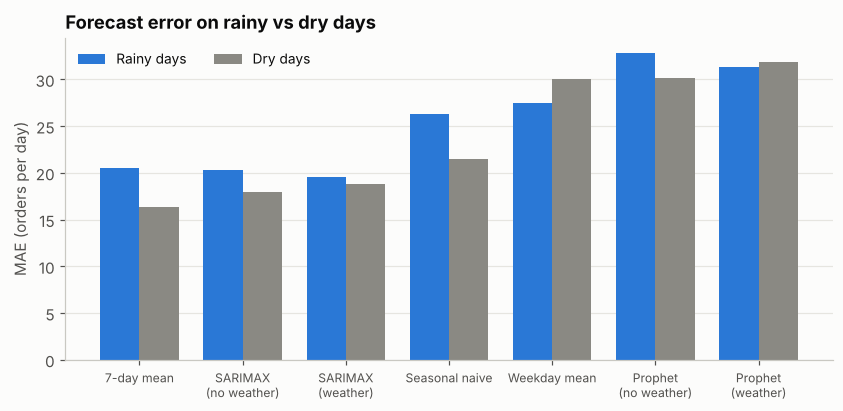

In [16]:
fcx = F.add_context(fc, real)
seg_rain = F.metrics(fcx, by=["rain"])
seg_day = F.metrics(fcx, by=["day_type"])
display(seg_rain[["n", "MAE", "MAPE_%", "bias"]].round(2))
display(seg_day[["n", "MAE", "MAPE_%", "bias"]].round(2))
pd.concat({"rain": seg_rain, "day_type": seg_day}).round(3).to_csv(RES / "metrics_by_segment.csv")

pr = seg_rain["MAE"].unstack("rain").loc[M.index]
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(pr)); w = 0.38
ax.bar(x - w/2, pr["rainy"], w, color=S.C["blue"], label="Rainy days")
ax.bar(x + w/2, pr["dry"], w, color=S.C["gray"], label="Dry days")
ax.set_xticks(x, [m.replace(" (", "\n(") for m in pr.index], fontsize=8)
ax.set_ylabel("MAE (orders per day)"); ax.set_title("Forecast error on rainy vs dry days"); ax.legend(ncol=2, loc="upper left")
save(fig, "fig07_error_rain_dry"); plt.show()

### 6. Residual checks for the best fitted model
If the model has captured the systematic structure, the out-of-sample errors should show no autocorrelation
(Ljung–Box p > 0.05) and be centred near zero. With 7-day-ahead forecasts, errors within a week share the same forecast origin, so
some autocorrelation is expected even for a good model.

Best fitted model: SARIMAX (no weather)
Ljung-Box p-values: {7: 0.0, 14: 0.0}
Residual mean 4.7, std 24.3


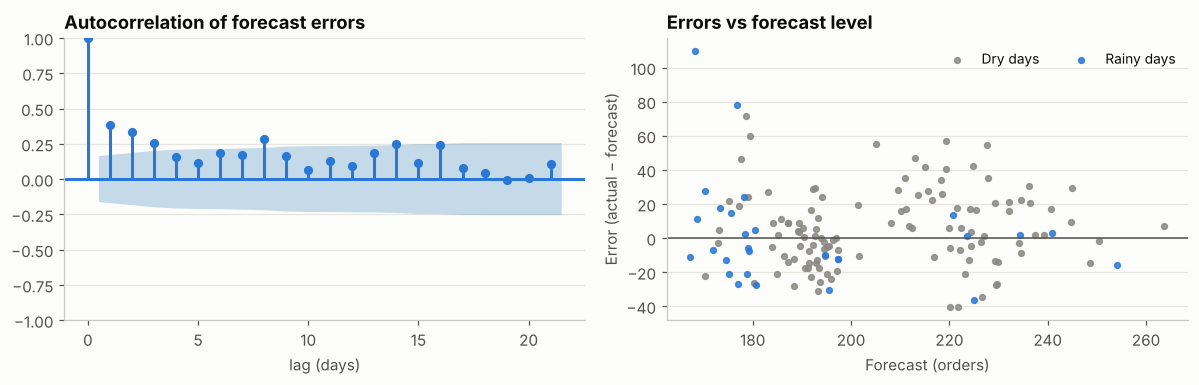

In [17]:
diag = F.residual_diagnostics(fc, best_model, lags=(7, 14))
print(f"Best fitted model: {best_model}")
print("Ljung-Box p-values:", {k: round(v, 3) for k, v in diag["ljung_box_p"].items()})
print(f"Residual mean {diag['resid_mean']:.1f}, std {diag['resid_std']:.1f}")

r = fcx[fcx["model"] == best_model].sort_values("date")
res = (r["y"] - r["yhat"]).to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
plot_acf(res, lags=21, ax=axes[0], color=S.C["blue"], vlines_kwargs={"colors": S.C["blue"]}, alpha=0.05)
axes[0].set_title("Autocorrelation of forecast errors"); axes[0].set_xlabel("lag (days)")
for name, col in [("dry", S.C["gray"]), ("rainy", S.C["blue"])]:
    s = r["rain"] == name
    axes[1].scatter(r.loc[s, "yhat"], res[s.to_numpy()], s=14, color=col, label=name.capitalize() + " days", alpha=0.85)
axes[1].axhline(0, color=S.C["ink2"], lw=1)
axes[1].set_xlabel("Forecast (orders)"); axes[1].set_ylabel("Error (actual − forecast)")
axes[1].set_title("Errors vs forecast level"); axes[1].legend(ncol=2)
fig.tight_layout(); save(fig, "fig08_residuals"); plt.show()

### 7. Longer horizon: fit once, forecast the last 8 weeks
Models are fitted once on the real days before the last 8 weeks and forecast all 56 days with no refitting. Settings are the ones
chosen on the first 127 days.

In [18]:
hold = F.static_holdout(real, models, test_days=TEST_DAYS)
H = F.metrics(hold).sort_values("MAE")
display(H.round(2)); H.round(3).to_csv(RES / "metrics_static_holdout.csv")

,n,MAE,RMSE,MAPE_%,bias,cover80_%
model,,,,,,
Weekday mean,56,16.77,19.64,9.30,-13.15,NaN
SARIMAX (no weather),56,17.49,20.27,9.72,-14.29,100.00
SARIMAX (weather),56,18.55,21.76,10.30,-15.25,94.64
7-day mean,56,23.60,26.32,13.12,-22.00,NaN
Seasonal naive,56,26.04,30.66,14.19,-22.00,NaN
Prophet (weather),56,64.72,67.77,35.33,-64.72,10.71
Prophet (no weather),56,75.46,77.95,41.17,-75.46,1.79


### 8. What the forecast means for operations
The planning buffer is how far above the forecast to prepare so that 90 % of days are covered.

In [19]:
buf_all = F.planning_buffer(fc, best_model, 0.90)
buf_rain = F.planning_buffer(fcx[fcx["rain"] == "rainy"], best_model, 0.90)
buf_dry = F.planning_buffer(fcx[fcx["rain"] == "dry"], best_model, 0.90)
buf = pd.DataFrame({"all days": buf_all, "rainy days": buf_rain, "dry days": buf_dry}).T.drop(columns="q").round(1)
display(buf); buf.to_csv(RES / "planning_buffer.csv")

,buffer_orders,buffer_pct_of_forecast
all days,32.6,15.5
rainy days,24.9,14.2
dry days,34.2,15.4


## Conclusions
The text below is generated from the results above, so it stays correct if the data changes.

In [20]:
def mae(m): return float(M.loc[m, "MAE"])
def pick(a, b):
    return B[(B["a"] == a) & (B["b"] == b)].iloc[0]
def sep(row): return "distinguishable from zero" if row["separable"] == "yes" else "not distinguishable from zero"
best_overall = M.index[0]
b_mean = pick(best_model, "7-day mean"); b_wd = pick(best_model, "Weekday mean")
b_sw = pick("SARIMAX (weather)", "SARIMAX (no weather)"); b_pw = pick("Prophet (weather)", "Prophet (no weather)")
heavy, rainf, hotf = W.loc["heavy_rain"], W.loc["is_rainy"], W.loc["is_hot"]
heavy_total = (np.exp(heavy["coef"] + rainf["coef"]) - 1) * 100
rain_mae, dry_mae = seg_rain.loc[(best_model, "rainy"), "MAE"], seg_rain.loc[(best_model, "dry"), "MAE"]
cov = M.loc[best_model].get("cover80_%", float("nan"))
dB = cmp_.loc[best_model]
fit_h = [m for m in H.index if m.startswith(("SARIMAX", "Prophet"))]
lines = [
    f"1. Scored days: {fc['date'].nunique()} real days ({fc['date'].min():%d %b} to {fc['date'].max():%d %b %Y}), 7-day-ahead forecasts refitted weekly. "
    f"Lowest MAE overall: {best_overall} at {mae(best_overall):.1f} orders/day ({M.loc[best_overall, 'MAE_%_of_mean']:.1f}% of mean daily orders). "
    f"Best fitted model: {best_model}, MAE {mae(best_model):.1f}.",
    f"2. Against the baselines: the seasonal-naive baseline scores {mae('Seasonal naive'):.1f}, the weekday-mean baseline {mae('Weekday mean'):.1f} "
    f"and the 7-day mean {mae('7-day mean'):.1f}. {best_model} vs weekday mean: {b_wd['mae_diff']:.1f} orders/day "
    f"(95% interval {b_wd['ci95_low']:.1f} to {b_wd['ci95_high']:.1f}). {best_model} vs the 7-day mean: {b_mean['mae_diff']:+.1f} "
    f"({b_mean['ci95_low']:.1f} to {b_mean['ci95_high']:.1f}), {sep(b_mean)}.",
    f"3. Forecast gain from weather: SARIMAX {b_sw['mae_diff']:+.1f} orders/day with weather vs without "
    f"(interval {b_sw['ci95_low']:.1f} to {b_sw['ci95_high']:.1f}, {sep(b_sw)}); Prophet {b_pw['mae_diff']:+.1f} "
    f"({b_pw['ci95_low']:.1f} to {b_pw['ci95_high']:.1f}, {sep(b_pw)}). A negative value means weather lowered the error. "
    f"These use observed weather for the forecast day, so they are a best case.",
    f"4. Estimated weather effect, adjusted for the level drift: any rain ≥ 2.5 mm {rainf['pct_effect']:+.1f}% "
    f"({rainf['pct_low']:+.1f}% to {rainf['pct_high']:+.1f}%); heavy rain adds {heavy['pct_effect']:+.1f}% beyond that "
    f"({heavy['pct_low']:+.1f}% to {heavy['pct_high']:+.1f}%), so a heavy-rain day is about {heavy_total:+.1f}% against a comparable dry day (point estimate); "
    f"hot day {hotf['pct_effect']:+.1f}% ({hotf['pct_low']:+.1f}% to {hotf['pct_high']:+.1f}%). The raw rainy-vs-dry gap is larger "
    f"({(raw.loc['rainy','mean'] / raw.loc['dry','mean'] - 1) * 100:+.1f}%) because rainy days cluster in months with a lower level.",
    f"5. By segment: {best_model} has MAE {rain_mae:.1f} on rainy days against {dry_mae:.1f} on dry days.",
    f"6. Synthetic history: for {best_model} the MAE changes by {dB['change']:+.1f} orders/day when 367 synthetic days are added to training "
    f"({sep(dB)}), even though that variant has seen information about the scored period.",
    f"7. Residuals of {best_model}: Ljung–Box p-values {', '.join(f'lag {k}: {v:.2f}' for k, v in diag['ljung_box_p'].items())} "
    f"({'no leftover autocorrelation' if min(diag['ljung_box_p'].values()) > 0.05 else 'some autocorrelation remains, expected with a shared 7-day forecast origin'}). "
    f"The 80% intervals covered {cov:.0f}% of days.",
    f"8. Fit-once hold-out of the last {TEST_DAYS} days: best fitted model {fit_h[0]} with MAE {H.loc[fit_h[0], 'MAE']:.1f}; baselines: weekday mean "
    f"{H.loc['Weekday mean', 'MAE']:.1f}, 7-day mean {H.loc['7-day mean', 'MAE']:.1f}, seasonal naive {H.loc['Seasonal naive', 'MAE']:.1f}. "
    f"{'The ranking differs from the rolling backtest' if H.index[0] != M.index[0] else 'The ranking matches the rolling backtest'}; "
    f"this is one 56-day window, so it is a check, not a second proof.",
    f"8b. Prophet: MAE {mae('Prophet (no weather)'):.1f} (no weather) and {mae('Prophet (weather)'):.1f} (weather) in the rolling backtest, worse than the weekday-mean baseline. "
    f"On the fit-once hold-out its forecasts sit {-H.loc['Prophet (weather)', 'bias']:.0f} orders/day above actual on average, consistent with a trend that kept "
    f"extending an earlier, higher level. It is not suited to a series whose level shifts like this one.",
    f"9. Planning: prepare for forecast + {buf_all['buffer_orders']:.0f} orders (about {buf_all['buffer_pct_of_forecast']:.0f}%) to cover 9 days in 10; "
    f"{buf_rain['buffer_orders']:.0f} on rainy days, {buf_dry['buffer_orders']:.0f} on dry days.",
]
display(Markdown("\n\n".join(lines)))

1. Scored days: 145 real days (09 May to 30 Sep 2025), 7-day-ahead forecasts refitted weekly. Lowest MAE overall: 7-day mean at 17.2 orders/day (8.2% of mean daily orders). Best fitted model: SARIMAX (no weather), MAE 18.4.

2. Against the baselines: the seasonal-naive baseline scores 22.4, the weekday-mean baseline 29.5 and the 7-day mean 17.2. SARIMAX (no weather) vs weekday mean: -11.1 orders/day (95% interval -18.1 to -5.2). SARIMAX (no weather) vs the 7-day mean: +1.2 (-1.0 to 3.3), not distinguishable from zero.

3. Forecast gain from weather: SARIMAX +0.5 orders/day with weather vs without (interval -0.1 to 1.3, not distinguishable from zero); Prophet +1.1 (-0.9 to 2.8, not distinguishable from zero). A negative value means weather lowered the error. These use observed weather for the forecast day, so they are a best case.

4. Estimated weather effect, adjusted for the level drift: any rain ≥ 2.5 mm -1.4% (-4.9% to +2.1%); heavy rain adds -3.9% beyond that (-7.1% to -0.6%), so a heavy-rain day is about -5.3% against a comparable dry day (point estimate); hot day -4.2% (-12.1% to +4.4%). The raw rainy-vs-dry gap is larger (-7.2%) because rainy days cluster in months with a lower level.

5. By segment: SARIMAX (no weather) has MAE 20.3 on rainy days against 17.9 on dry days.

6. Synthetic history: for SARIMAX (no weather) the MAE changes by +4.6 orders/day when 367 synthetic days are added to training (distinguishable from zero), even though that variant has seen information about the scored period.

7. Residuals of SARIMAX (no weather): Ljung–Box p-values lag 7: 0.00, lag 14: 0.00 (some autocorrelation remains, expected with a shared 7-day forecast origin). The 80% intervals covered 88% of days.

8. Fit-once hold-out of the last 56 days: best fitted model SARIMAX (no weather) with MAE 17.5; baselines: weekday mean 16.8, 7-day mean 23.6, seasonal naive 26.0. The ranking differs from the rolling backtest; this is one 56-day window, so it is a check, not a second proof.

8b. Prophet: MAE 30.7 (no weather) and 31.8 (weather) in the rolling backtest, worse than the weekday-mean baseline. On the fit-once hold-out its forecasts sit 65 orders/day above actual on average, consistent with a trend that kept extending an earlier, higher level. It is not suited to a series whose level shifts like this one.

9. Planning: prepare for forecast + 33 orders (about 15%) to cover 9 days in 10; 25 on rainy days, 34 on dry days.

## Limits of this analysis
* **One outlet, nine months of real data.** The test period is 9 May – 30 Sep 2025, mostly dry season: 28 of the 145 scored days are rainy.
  Weather estimates are therefore wide and say little about the rainy season.
* **No yearly cycle.** Under a year of real data cannot support a yearly term; it would need at least two seasons to test.
* **Level drift is not explained by our variables.** The monthly swings (for example April vs June) come from something not in the data
  (holidays, outlet changes, promotions); the models follow the drift but cannot anticipate it.
* **Oracle weather.** The weather models are given the forecast day's observed weather. Using a weather forecast would raise their error.
* **Settings were chosen on the first 127 real days**, which keeps the backtest honest but means the chosen orders may not be optimal.
* **Synthetic days.** They are excluded from scoring. As training history they are generated from parameters fitted on all 272 real
  days, so that variant is not a clean out-of-sample test.
* **Not the same horizon as P5.** P5's model-selection table (`docs/p5_model_selection.md`) forecasts one day ahead; this notebook forecasts
  seven days ahead, so MAEs are not directly comparable. The scored days are the same.
* **Shared thresholds.** The weather flags (2.5 mm, 15 mm, 33 °C) are the team's regime definitions.